# Random Forest Hyperparameter Tuning

## 1. Objective

The objective of this notebook is to tune Random Forest for predicting restaurant `weighted_rating`, using only the training data and 5-fold cross-validation.

The best settings, their validation scores and a refit model are meant to feed the ensemble notebook.

## 2. Problem Statement

This project predicts the weighted rating of a restaurant from the prepared restaurant features (cuisine, location, menu, pricing and geography).

**Target Variable:** `weighted_rating`

**Problem Type:** Supervised Machine Learning - Regression

## 3. Evaluation Metrics

The models are evaluated with:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE), the main metric for choosing settings
- R-squared (R²)

Every score is the mean and standard deviation over the same 5 folds (`KFold`, `shuffle=True`, `random_state=42`). The standard deviation is the population standard deviation (`ddof=0`) of the 5 fold scores, the same convention the search already used.

## 4. Approach

A Random Forest is a large group of decision trees. Each tree sees a random sample of rows and a random subset of columns at each split, and the forest averages their predictions.

Tuning uses random search. Each trial draws one set of settings from the ranges in step 3 (fixed seed, so the draws can be repeated) and scores it with 5-fold cross-validation on the training rows. The mean RMSE is the only score used to choose. Random search was kept because it needs no extra library, is repeatable from one seed, and covers the space without assuming its shape.

After the search, the best settings are run through 5-fold cross-validation once more to record MAE, RMSE and R² for every fold. Then the model is refit on all training rows.

The recorded run of 12 trials took 36.8 minutes, because every trial is 5 model fits on 53,574 rows. `QUICK = True` runs fewer trials.

## 5. Expected Outcome

A set of best settings, a validation table with mean ± std for MAE, RMSE and R², and a model refit on the full training split.

## 6. How the test set was used

The test set is not used in this notebook. It is not loaded, and it plays no part in any choice here. All tuning and all choices use only the training data with 5-fold cross-validation. The test set is used once, at the end of the project, for the single final chosen model or ensemble, in the last cell of the ensemble notebook.

## 1. Imports and configuration

The seed, number of folds and search budget are set here. The notebook loads the prepared training features and target from `data/processed`, as produced by the project's preprocessing workflow. It does not recreate preprocessing or load test data.

In [1]:
import os, time, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from IPython.display import Markdown, display as idisplay

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)

# ================================ CONFIG ================================
PROCESSED_DIR = Path("data/processed")

TARGET = "weighted_rating"
RANDOM_STATE = 42
CV_FOLDS = 5

SAMPLE_ROWS = None   # Keep None to use all training rows; a subset is only for a dry run
QUICK = False        # Keep False for the full 12-trial search used in this report

if QUICK:
    N_TRIALS, TIME_BUDGET_MIN = 4, 10
else:
    N_TRIALS, TIME_BUDGET_MIN = 12, None

print("Training data :", PROCESSED_DIR)
print(f"Search budget : {N_TRIALS} random trials x {CV_FOLDS} folds")


Dataset       : Clean_Restaurant_Dataset.csv
Search budget : 12 random trials x 5 folds


## 2. Load the prepared training data

This notebook loads `X_train_processed.csv` and `y_train.csv` from `data/processed`, as produced by the project's preprocessing workflow. It does not recreate preprocessing and does not load or use test data.

In [3]:
PROCESSED_FILES = ["X_train_processed.csv", "y_train.csv"]
missing = [name for name in PROCESSED_FILES if not (PROCESSED_DIR / name).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in '{PROCESSED_DIR}'. "
        "Run the project's preprocessing workflow first to create the processed training files."
    )

X_train = pd.read_csv(PROCESSED_DIR / "X_train_processed.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")

if len(X_train) != len(y_train):
    raise ValueError("X_train and y_train have different numbers of rows.")

FIT_KWARGS = {}

print("Loaded prepared training data from:", PROCESSED_DIR)
print("Train:", X_train.shape)
print("Missing values (train):", int(X_train.isna().sum().sum()))


Loaded the existing training data from data/processed
Train: (53574, 263)
Missing values (train): 0


## 3. Search space

Each trial draws one value for each setting from these ranges.

| Parameter | Range | What it does |
|---|---|---|
| `n_estimators` | 200 to 900 (step 100) | Number of trees |
| `max_depth` | 8 to 40 | Tree depth cap |
| `min_samples_split` | 2 to 20 | Minimum rows needed to split a node |
| `min_samples_leaf` | 1 to 20 | Minimum rows in a leaf, the main smoothing control |
| `max_features` | 0.10 to 1.00 | Fraction of features offered to each split |

## 4. Random search

The following cell executes the complete random search. Each trial is scored with the same 5-fold training-only cross-validation split. A checkpoint is saved atomically after every completed trial, so an interrupted run can resume without repeating completed trials.

In [ ]:
def sample_params(rng):
    """Draw one configuration uniformly from the ranges in the table above."""
    return {
        "n_estimators": int(rng.choice([200, 300, 400, 500, 600, 700, 800, 900])),
        "max_depth": int(rng.randint(8, 41)),
        "min_samples_split": int(rng.randint(2, 21)),
        "min_samples_leaf": int(rng.randint(1, 21)),
        "max_features": float(rng.uniform(0.10, 1.00)),
    }


def make_model(**params):
    settings = dict(random_state=RANDOM_STATE, n_jobs=-1)
    settings.update(params)
    return RandomForestRegressor(**settings)


X_values = np.asarray(y_train)

if SAMPLE_ROWS:
    keep = np.random.RandomState(RANDOM_STATE).choice(
        len(X_train), min(SAMPLE_ROWS, len(X_train)), replace=False)
    X_fit, y_fit = X_train.iloc[keep], X_values[keep]
    print(f"SAMPLE_ROWS is active - CV on {len(keep):,} rows. Dry run only, not for results.")
else:
    X_fit, y_fit = X_train, X_values
    print(f"5-fold CV on the full training split: {len(X_fit):,} rows")

cv_folds = list(KFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X_fit))

def cv_score(params):
    """Mean and standard deviation of the 5-fold CV RMSE for one configuration."""
    fold_rmses = []
    for tri, tei in cv_folds:
        model = make_model(**params)
        model.fit(X_fit.iloc[tri], y_fit[tri], **FIT_KWARGS)
        pred = model.predict(X_fit.iloc[tei])
        fold_rmses.append(float(np.sqrt(mean_squared_error(y_fit[tei], pred))))
    return float(np.mean(fold_rmses)), float(np.std(fold_rmses))


# A checkpoint is written after every completed trial. If a trial is interrupted,
# the last completed checkpoint is loaded and that unfinished trial is repeated.
CHECKPOINT_DIR = Path("artifacts")
CHECKPOINT_PATH = CHECKPOINT_DIR / "random_forest_search_checkpoint.pkl"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

SEARCH_CONFIG = {
    "n_trials": N_TRIALS,
    "random_state": RANDOM_STATE,
    "cv_folds": CV_FOLDS,
    "sample_rows": SAMPLE_ROWS,
    "n_rows": len(X_fit),
    "n_features": X_fit.shape[1],
    "feature_columns": list(X_fit.columns),
}

def save_search_checkpoint():
    """Atomically save completed trials and all state needed to resume."""
    payload = {
        "config": SEARCH_CONFIG,
        "trials": TRIALS,
        "rng_state": rng.get_state(),
        "best_params": best_params,
        "cv_rmse": cv_rmse,
        "cv_std": cv_std,
    }
    temporary_path = CHECKPOINT_PATH.with_suffix(".tmp")
    with open(temporary_path, "wb") as file:
        pickle.dump(payload, file, protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(temporary_path, CHECKPOINT_PATH)


rng = np.random.RandomState(RANDOM_STATE)
if CHECKPOINT_PATH.exists():
    with open(CHECKPOINT_PATH, "rb") as file:
        saved = pickle.load(file)

    if saved.get("config") != SEARCH_CONFIG:
        raise ValueError(
            f"An existing checkpoint was found at {CHECKPOINT_PATH}, but its "
            "search/data configuration does not match this run. Move or delete "
            "that checkpoint to intentionally start a fresh search."
        )

    TRIALS = saved["trials"]
    rng.set_state(saved["rng_state"])
    best_params = saved["best_params"]
    cv_rmse = saved["cv_rmse"]
    cv_std = saved["cv_std"]
    print(f"Resuming from checkpoint: {len(TRIALS)}/{N_TRIALS} trials already complete.")
else:
    TRIALS = []
    best_params, cv_rmse, cv_std = None, float("inf"), float("nan")
    print("No checkpoint found. Starting a new random search.")

T0 = time.time()
for trial in range(len(TRIALS), N_TRIALS):
    if TIME_BUDGET_MIN and (time.time() - T0) / 60 > TIME_BUDGET_MIN:
        print(f"Time budget of {TIME_BUDGET_MIN} min reached - stopping after {trial} trials.")
        break

    # The RNG state is checkpointed only after a trial completes. If this trial
    # is interrupted, restarting draws the same parameters and retries this trial.
    params = sample_params(rng)
    score, spread = cv_score(params)
    TRIALS.append({**params, "cv_rmse": score, "fold_std": spread})

    improved = score < cv_rmse
    if improved:
        best_params, cv_rmse, cv_std = params, score, spread

    save_search_checkpoint()
    print(f"trial {trial + 1:2d} | RMSE {score:.5f} (std {spread:.5f}) | best {cv_rmse:.5f}"
          + ("   <- best" if improved else ""))
    print(f"  Checkpoint saved ({len(TRIALS)}/{N_TRIALS} trials).")

print(f"\nFinished {len(TRIALS)}/{N_TRIALS} trials in {(time.time() - T0) / 60:.1f} min")
print(f"Checkpoint: {CHECKPOINT_PATH}")


## 5. Search results

The best mean validation RMSE, the corresponding hyperparameters and the ranked trial table are shown below.

In [5]:
trial_table = pd.DataFrame(TRIALS)
trial_table.insert(0, "trial", range(1, len(trial_table) + 1))
trials_df = trial_table.sort_values("cv_rmse").reset_index(drop=True)

print(f"Best 5-fold CV RMSE : {cv_rmse:.5f}")
print(f"Fold-to-fold std    : {cv_std:.5f}")
print("Best parameters     :")
for key, value in best_params.items():
    print(f"  {key:18s} {value}")

print("\nTop 10 trials by CV RMSE:")
display(trials_df.head(10).round(5))

Best 5-fold CV RMSE : 0.13493
Fold-to-fold std    : 0.00105
Best parameters     :
  n_estimators       500
  max_depth          31
  min_samples_split  4
  min_samples_leaf   2
  max_features       0.7497988950401423

Top 10 trials by CV RMSE:


,trial,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,cv_rmse,fold_std
0,3,500,31,4,2,0.74980,0.13493,0.00105
1,1,800,36,16,11,0.80172,0.13615,0.00112
2,2,600,26,12,11,0.87956,0.13634,0.00114
3,5,600,32,18,10,0.14200,0.13658,0.00111
4,6,500,23,16,15,0.65655,0.13664,0.00113
5,8,200,25,5,14,0.82756,0.13665,0.00119
6,11,700,24,5,18,0.69627,0.13694,0.00113
7,9,200,33,3,20,0.31692,0.13732,0.00114
8,12,300,13,11,4,0.26637,0.13736,0.00104
9,10,500,14,13,8,0.13095,0.13798,0.00110


## 6. Convergence

Each point is one trial's mean RMSE; the line shows the best score found up to that trial.

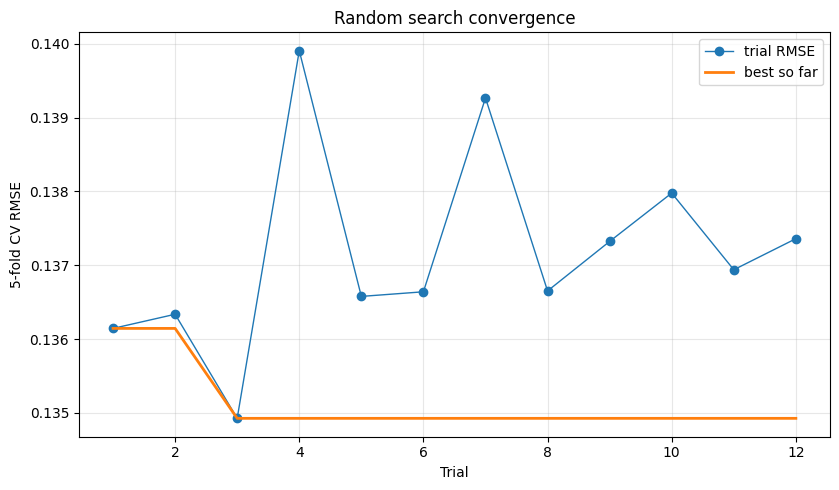

Best configuration found at trial 3 of 12.
If the best-so-far line flattened well before the last trial, the budget was already enough.


In [6]:
history = trial_table.sort_values("trial")

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(history["trial"], history["cv_rmse"], marker="o", linewidth=1, label="trial RMSE")
ax.plot(history["trial"], history["cv_rmse"].cummin(), linewidth=2, label="best so far")
ax.set_xlabel("Trial")
ax.set_ylabel("5-fold CV RMSE")
ax.set_title("Random search convergence")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

best_trial_number = int(history.loc[history["cv_rmse"].idxmin(), "trial"])
print(f"Best configuration found at trial {best_trial_number} of {len(history)}.")
print("If the best-so-far line flattened well before the last trial, the budget was already enough.")

### Observation

- Trial RMSE ranged from 0.13493 to 0.13991 over 12 trials, a spread of 0.00498.
- The best setting was trial 3, with mean 5-fold RMSE **0.13493** and a fold standard deviation of 0.00105.
- The second best trial scored 0.13615, which is 0.00122 higher. 3 of the 12 trials were within 0.0015 of the best, so settings within that gap are close to ties.
- Settings at or near the edge of their search range: `min_samples_split` = 4 (close to the lower edge); `min_samples_leaf` = 2 (close to the lower edge). The best value may lie outside the range that was searched. The ranges were not changed, as requested.
- The other settings ended inside their ranges.
- The best setting came at trial 3 of 12. No later trial improved on it.

## 7. Cross-validation of the best settings

The best settings are evaluated again on the same five folds to record MAE, RMSE and R² for each fold, together with training RMSE. Out-of-fold predictions are retained for the residual plots.

In [5]:
# The search cell sets best_params automatically from the lowest mean CV RMSE.
# Do not hard-code the previous run's settings here: a fresh run must use
# the winner produced by its own completed search.
assert len(TRIALS) == N_TRIALS, (
    f"Expected {N_TRIALS} completed trials, but found {len(TRIALS)}. "
    "Check the search output before continuing."
)
assert best_params is not None, "The search did not produce a best configuration."
print("Best configuration selected from this run:")
print(best_params)
print(f"Best 5-fold CV RMSE: {cv_rmse:.5f} (fold std: {cv_std:.5f})")


In [6]:
fold_rows = []
oof_pred = np.zeros(len(X_fit))
for k, (tri, tei) in enumerate(cv_folds, start=1):
    model = make_model(**best_params)
    model.fit(X_fit.iloc[tri], y_fit[tri], **FIT_KWARGS)
    pred_va = model.predict(X_fit.iloc[tei])
    pred_tr = model.predict(X_fit.iloc[tri])
    oof_pred[tei] = pred_va
    fold_rows.append({
        "Fold": k,
        "MAE": mean_absolute_error(y_fit[tei], pred_va),
        "RMSE": float(np.sqrt(mean_squared_error(y_fit[tei], pred_va))),
        "R2": r2_score(y_fit[tei], pred_va),
        "Train RMSE": float(np.sqrt(mean_squared_error(y_fit[tri], pred_tr))),
    })

fold_df = pd.DataFrame(fold_rows)
display(fold_df.style
        .format({"MAE": "{:.5f}", "RMSE": "{:.5f}", "R2": "{:.5f}", "Train RMSE": "{:.5f}"})
        .hide(axis="index")
        .set_caption("Best settings, per fold (MAE, RMSE, R2 on the validation fold; Train RMSE on the fold's training rows)"))

# Same convention as the search: population std (ddof=0) across the 5 folds.
cv_summary = {m: (fold_df[m].mean(), fold_df[m].std(ddof=0)) for m in ["MAE", "RMSE", "R2", "Train RMSE"]}
for m, (mu, sd) in cv_summary.items():
    print(f"{m:10s} mean {mu:.5f} | std {sd:.5f}")

print(f"\nMean RMSE found by the search : {cv_rmse:.5f}")
print(f"Mean RMSE re-computed here    : {cv_summary['RMSE'][0]:.5f}")

Fold,MAE,RMSE,R2,Train RMSE
1,0.09860,0.13355,0.37547,0.06167
2,0.09941,0.13664,0.37452,0.06128
3,0.09975,0.13539,0.35443,0.06143
4,0.09896,0.13482,0.37595,0.06139
5,0.09915,0.13423,0.36436,0.06185


MAE        mean 0.09917 | std 0.00039
RMSE       mean 0.13493 | std 0.00105
R2         mean 0.36895 | std 0.00842
Train RMSE mean 0.06152 | std 0.00021

Mean RMSE found by the search : 0.13493
Mean RMSE re-computed here    : 0.13493


### Observation

The table above reports the mean and population standard deviation across the five validation folds. The recomputed validation RMSE should agree with the best search RMSE, subject only to numerical variation.

## 8. Final refit on all training data

After model selection and cross-validation, the best configuration is refit on all available training rows. This fitted model is not scored on those same rows; the 5-fold validation results remain the estimate of generalisation performance.

In [7]:
final_model = make_model(**best_params)
t0 = time.time()
final_model.fit(X_train, y_train, **FIT_KWARGS)
N_REFIT_ROWS = len(X_train)

print(f"Rows used for the final refit: {N_REFIT_ROWS:,} (all training rows, the 5 folds combined)")
print(f"Refit time: {time.time() - t0:.1f}s")
print("The refit model is not scored here.")
print("\nbest_params =", best_params)

Rows used for the final refit: 53,574 (all training rows, the 5 folds combined)
Refit time: 141.5s
The refit model is not scored here.

best_params = {'n_estimators': 500, 'max_depth': 31, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 0.7497988950401423}


## 9. Feature importance

The features the refit model relied on most. This uses only the fitted model and the training columns.

Top 20 features:


,0
vegetarian_menu_ratio,0.0866
city,0.0791
log_menu_item_count,0.0324
locality_latitude,0.0322
average_cost_for_two,0.0297
locality_longitude,0.0283
cuisine,0.0244
menu_category_diversity,0.0204
school_nearest_distance_meters,0.0198
local_district_wealth_index,0.0198


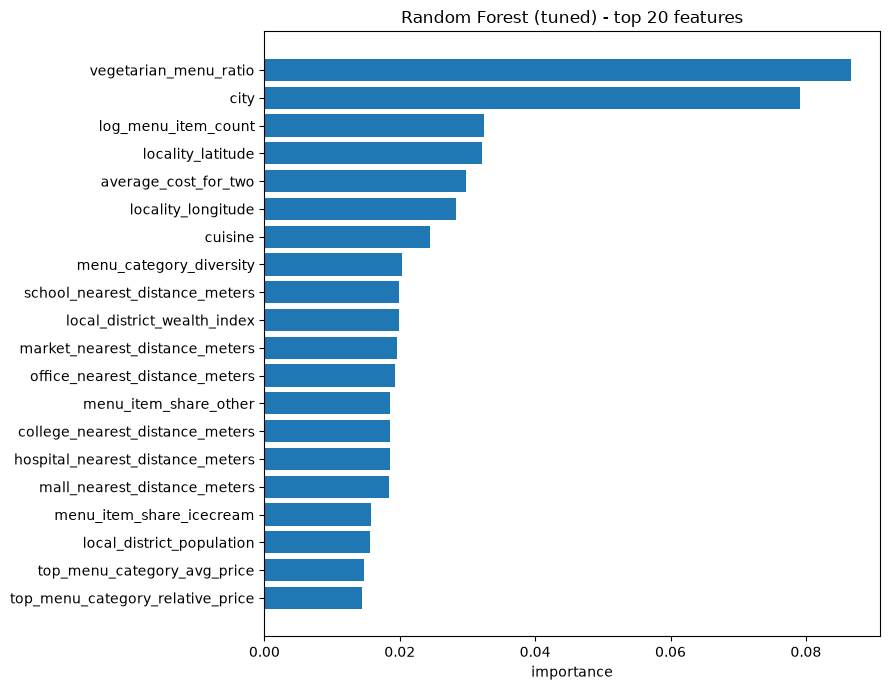

In [8]:
if hasattr(final_model, "get_feature_importance"):
    importance_values = final_model.get_feature_importance()
elif hasattr(final_model, "feature_importances_"):
    importance_values = final_model.feature_importances_
else:
    importance_values = np.abs(final_model.coef_)

importance_series = pd.Series(importance_values, index=X_train.columns).sort_values(ascending=False)

print("Top 20 features:")
display(importance_series.head(20).to_frame().round(4))

fig, ax = plt.subplots(figsize=(9, 7))
top = importance_series.head(20)[::-1]
ax.barh(top.index, top.values)
ax.set_title("Random Forest (tuned) - top 20 features")
ax.set_xlabel("importance")
plt.tight_layout()
plt.show()
plt.close(fig)

### Observation

The top five features were `vegetarian_menu_ratio` (0.0866), `city` (0.0791), `log_menu_item_count` (0.0324), `locality_latitude` (0.0322) and `average_cost_for_two` (0.0297) (the forest's impurity-based importance scores, which add up to 1). Menu, location and price features carry most of the weight. This shows what the model used, not what causes a rating.

## 10. Residuals on the validation folds

These plots use the out-of-fold predictions from step 7, so each training row is predicted by a model that did not train on that row.

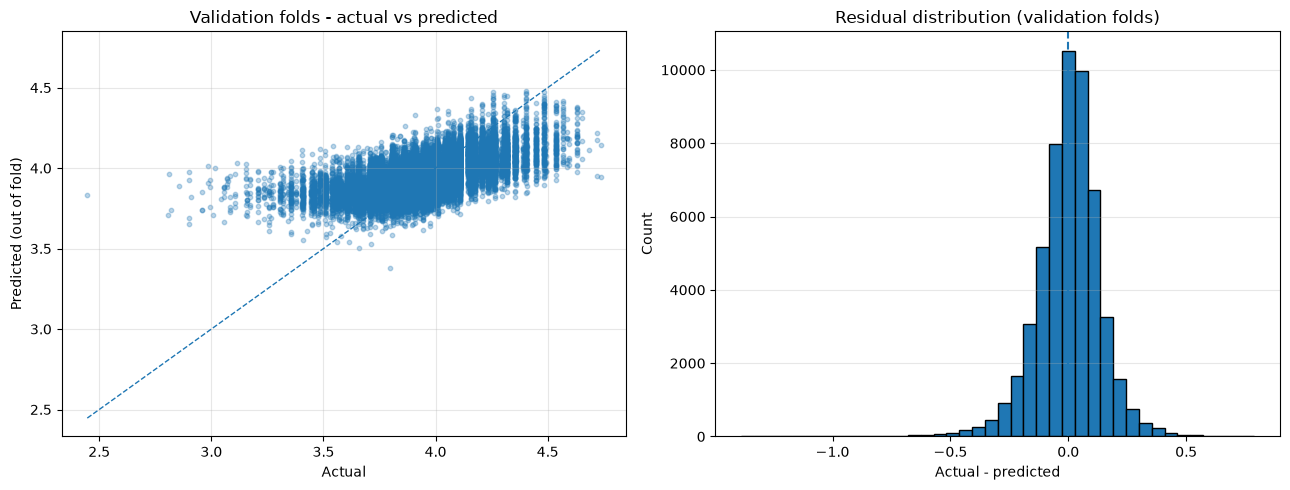

Mean residual : 0.00093
Residual std  : 0.13493


In [9]:
oof_residuals = y_fit - oof_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_fit, oof_pred, alpha=0.3, s=10)
lims = [min(y_fit.min(), oof_pred.min()), max(y_fit.max(), oof_pred.max())]
axes[0].plot(lims, lims, "--", linewidth=1)
axes[0].set_title("Validation folds - actual vs predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted (out of fold)")
axes[0].grid(alpha=0.3)

axes[1].hist(oof_residuals, bins=40, edgecolor="black")
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Residual distribution (validation folds)")
axes[1].set_xlabel("Actual - predicted")
axes[1].set_ylabel("Count")
axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close(fig)

print(f"Mean residual : {oof_residuals.mean():.5f}")
print(f"Residual std  : {oof_residuals.std():.5f}")

## 11. Final validation table

The table collects the 5-fold validation mean ± standard deviation for MAE, RMSE and R², plus the number of rows used in the final refit. It contains no test-set results.

In [10]:
def mean_std(metric):
    mu, sd = cv_summary[metric]
    return f"{mu:.5f} ± {sd:.5f}"


final_table = pd.DataFrame([{
    "Model": "Random Forest (tuned)",
    "MAE (mean ± std)": mean_std("MAE"),
    "RMSE (mean ± std)": mean_std("RMSE"),
    "R2 (mean ± std)": mean_std("R2"),
    "Rows in final refit": f"{N_REFIT_ROWS:,}",
}])
display(final_table.style.hide(axis="index")
        .set_caption("5-fold validation results (training data only)"))

Model,MAE (mean ± std),RMSE (mean ± std),R2 (mean ± std),Rows in final refit
Random Forest (tuned),0.09917 ± 0.00039,0.13493 ± 0.00105,0.36895 ± 0.00842,"53,574"


In [11]:
# --- Summary metrics (train-side only, no test set, nothing saved) ---
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_all = X_fit if "X_fit" in globals() else X_train
y_all = np.asarray(y_fit if "y_fit" in globals() else y_train)
fit_kw = FIT_KWARGS if "FIT_KWARGS" in globals() else {}
params = best_params

per_fold = []
for k, (tr_idx, va_idx) in enumerate(cv_folds, start=1):
    X_tr, y_tr = X_all.iloc[tr_idx], y_all[tr_idx]
    X_va, y_va = X_all.iloc[va_idx], y_all[va_idx]
    m = make_model(**params)
    m.fit(X_tr, y_tr, **fit_kw)
    pred_tr = m.predict(X_tr)
    pred_va = m.predict(X_va)
    per_fold.append({
        "Fold": k,
        "Train MAE": mean_absolute_error(y_tr, pred_tr),
        "Train RMSE": float(np.sqrt(mean_squared_error(y_tr, pred_tr))),
        "Train R2": r2_score(y_tr, pred_tr),
        "Val MAE": mean_absolute_error(y_va, pred_va),
        "Val RMSE": float(np.sqrt(mean_squared_error(y_va, pred_va))),
        "Val R2": r2_score(y_va, pred_va),
    })

fold_df = pd.DataFrame(per_fold)
train_avg = fold_df[["Train MAE", "Train RMSE", "Train R2"]].mean()
val_avg = fold_df[["Val MAE", "Val RMSE", "Val R2"]].mean()

m_full = make_model(**params)
m_full.fit(X_all, y_all, **fit_kw)
pred_full = m_full.predict(X_all)
overall = pd.Series({
    "Overall MAE": mean_absolute_error(y_all, pred_full),
    "Overall RMSE": float(np.sqrt(mean_squared_error(y_all, pred_full))),
    "Overall R2": r2_score(y_all, pred_full),
})

summary = pd.DataFrame([
    {"Split": "Train (avg over folds)", "MAE": train_avg["Train MAE"], "RMSE": train_avg["Train RMSE"], "R2": train_avg["Train R2"]},
    {"Split": "Validation (avg over folds)", "MAE": val_avg["Val MAE"], "RMSE": val_avg["Val RMSE"], "R2": val_avg["Val R2"]},
    {"Split": "Overall (train+val included)", "MAE": overall["Overall MAE"], "RMSE": overall["Overall RMSE"], "R2": overall["Overall R2"]},
])

print("Best params:", params)
print("\nPer-fold metrics:")
display(fold_df.round(6))
print("\nSummary (this notebook):")
display(summary.round(6))
print("\nCopyable summary:")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

Best params: {'n_estimators': 500, 'max_depth': 31, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 0.7497988950401423}

Per-fold metrics:


,Fold,Train MAE,Train RMSE,Train R2,Val MAE,Val RMSE,Val R2
0,1,0.042936,0.061669,0.868547,0.098600,0.133554,0.375468
1,2,0.042846,0.061281,0.868748,0.099405,0.136642,0.374521
2,3,0.042721,0.061430,0.869759,0.099750,0.135388,0.354432
3,4,0.042734,0.061389,0.869110,0.098964,0.134823,0.375950
4,5,0.043136,0.061852,0.868022,0.099148,0.134230,0.364358



Summary (this notebook):


,Split,MAE,RMSE,R2
0,Train (avg over folds),0.042875,0.061524,0.868837
1,Validation (avg over folds),0.099173,0.134928,0.368946
2,Overall (train+val included),0.043044,0.061548,0.868738



Copyable summary:
                       Split      MAE     RMSE       R2
      Train (avg over folds) 0.042875 0.061524 0.868837
 Validation (avg over folds) 0.099173 0.134928 0.368946
Overall (train+val included) 0.043044 0.061548 0.868738


# Summary

## 1. Results

5-fold validation on the training data (mean ± std over the 5 folds). Lower is better for MAE and RMSE, higher is better for R².

| Model | MAE | RMSE | R² | Rows in final refit |
|---|---:|---:|---:|---:|
| Random Forest (tuned) | 0.09917 ± 0.00039 | 0.13493 ± 0.00105 | 0.36895 ± 0.00842 | 53,574 |

These are the saved results from the five-fold training-only validation run. Running the notebook from a fresh kernel recalculates them.

## 2. Key Findings

- The best Random Forest settings (500 trees, depth 31, `min_samples_split` 4, `min_samples_leaf` 2, `max_features` about 0.750) reached a mean 5-fold RMSE of 0.13493 (std 0.00105), found at trial 3 of 12.
- Across the 12 completed trials the mean RMSE ranged from 0.13493 to 0.13991. 3 trials were within 0.0015 of the best.
- 2 of the 5 tuned settings ended at or near the edge of their range (`min_samples_split` = 4 (close to the lower edge); `min_samples_leaf` = 2 (close to the lower edge)).
- The largest feature importances were `vegetarian_menu_ratio` (0.0866), `city` (0.0791), `log_menu_item_count` (0.0324), `locality_latitude` (0.0322) and `average_cost_for_two` (0.0297) (the forest's impurity-based importance scores, which add up to 1). Importance shows what the model used, not what causes a rating.
- The five-fold validation results are MAE 0.09917, RMSE 0.13493 and R² 0.36895 (means; standard deviations are shown in the table).

## 3. Notes and Limitations

- **The best score is slightly optimistic.** The best setting is picked on the same 5 folds that give its reported score.
- **Fold-to-fold noise sets the bar.** Gaps below about 0.0015 in mean RMSE are treated as ties. This is a rule of thumb, not a tested threshold.
- **The standard deviation describes spread across 5 folds.** It is not a confidence interval.
- **Train/validation gap.** In an earlier run, the refit model scored RMSE 0.06155 on its own training rows, against a mean validation RMSE of 0.13493. Step 7 prints the per-fold train RMSE for the same comparison.
- **Search size.** 12 trials is small for five settings. The result is a good region, not the exact optimum.
- **Baseline comparison.** The baseline notebook scored one 80/20 split, and its CatBoost used early stopping on that split. Those numbers are not like for like with the 5-fold results here, so no comparison is made.
- **Search checkpoint.** Completed trials and the random-number generator state are saved after each trial in `artifacts/random_forest_search_checkpoint.pkl`. On restart, the search resumes from the next unfinished trial. To deliberately start a completely new search, remove that checkpoint first.
- **The test set is not used here.** See section 6 at the top.

## 4. Conclusion and Next Steps

The best Random Forest settings by mean 5-fold validation RMSE are the ones printed in step 5. The model refit on all 53,574 training rows is ready for the ensemble notebook, which will decide on out-of-fold predictions whether Random Forest is used and with what weight. The test set stays untouched until the final cell of that notebook.

Next steps: run the notebook from the first cell in a fresh environment with the required training data and packages. The search will execute again using the configured 12-trial budget.